In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_excel('/content/drive/MyDrive/Lab_Data/student_expense_dataset.xlsx')

df.head()

,Rent,Utilities,Food Expense,Travel Cost,Clothing,Outings,Monthly Expense
0,13677,3074,3849,3321,2246,3568,30735
1,17677,1937,6302,1500,3862,2146,34439
2,16626,1795,8816,2607,1695,5888,38457
3,16949,2079,7774,1071,3091,2109,34118
4,17636,2647,5995,3679,3678,500,35195


In [ ]:
df.head()
df.info()
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Rent              200 non-null    int64
 1   Utilities         200 non-null    int64
 2   Food Expense      200 non-null    int64
 3   Travel Cost       200 non-null    int64
 4   Clothing          200 non-null    int64
 5   Outings           200 non-null    int64
 6   Monthly Expense   200 non-null    int64
dtypes: int64(7)
memory usage: 11.1 KB
['Rent ', 'Utilities ', 'Food Expense ', 'Travel Cost ', 'Clothing ', 'Outings ', 'Monthly Expense ']


In [ ]:
df.isnull().sum()

,0
Rent,0
Utilities,0
Food Expense,0
Travel Cost,0
Clothing,0
Outings,0
Monthly Expense,0


In [ ]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Rent', 'Utilities', 'Food Expense', 'Travel Cost', 'Clothing', 'Outings', 'Monthly Expense']


In [ ]:
X = df[['Rent',
        'Utilities',
        'Food Expense',
        'Travel Cost',
        'Clothing',
        'Outings']]

y = df['Monthly Expense']

In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (200, 7)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (160, 6)
Testing Shape: (40, 6)


In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("Linear Regression Results")
print("MAE =", mean_absolute_error(y_test, pred_lr))
print("MSE =", mean_squared_error(y_test, pred_lr))
print("RMSE =", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("R2 Score =", r2_score(y_test, pred_lr))

Linear Regression Results
MAE = 761.9220701935931
MSE = 766900.3289846015
RMSE = 875.7284561921016
R2 Score = 0.96906576882043


In [ ]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=42)

dt.fit(X_train, y_train)
pred_dt = dt.predict(X_test)

In [ ]:
print("Decision Tree Results")

print("MAE =", mean_absolute_error(y_test, pred_dt))
print("MSE =", mean_squared_error(y_test, pred_dt))
print("RMSE =", np.sqrt(mean_squared_error(y_test, pred_dt)))
print("R2 Score =", r2_score(y_test, pred_dt))

Decision Tree Results
MAE = 2231.575
MSE = 6985044.925
RMSE = 2642.923556404914
R2 Score = 0.7182463139692166


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

In [ ]:
print("Random Forest Results")

print("MAE =", mean_absolute_error(y_test, pred_rf))
print("MSE =", mean_squared_error(y_test, pred_rf))
print("RMSE =", np.sqrt(mean_squared_error(y_test, pred_rf)))
print("R2 Score =", r2_score(y_test, pred_rf))

Random Forest Results
MAE = 1438.52525
MSE = 2976962.2491424996
RMSE = 1725.3875649089684
R2 Score = 0.8799191564440239


In [ ]:
comparison = pd.DataFrame({

    "Algorithm":[
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE":[
        761.9220701935931,
        2231.575,
        1438.52525
    ],
    "MSE":[
        766900.3289846015,
        6985044.925,
        2976962.2491424996
    ],
    "RMSE":[
        875.7284561921016,
        2642.923556404914,
        1725.3875649089684
    ],
    "R2 Score":[
        0.96906576882043,
        0.7182463139692166,
        0.8799191564440239
    ]
})
comparison.sort_values(
    by="R2 Score",
    ascending=False
)

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,761.92207,7.669003e+05,875.728456,0.969066
2,Random Forest,1438.52525,2.976962e+06,1725.387565,0.879919
1,Decision Tree,2231.57500,6.985045e+06,2642.923556,0.718246


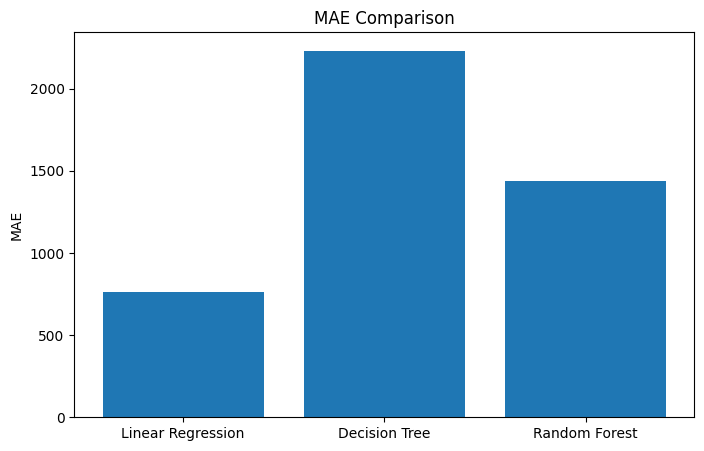

In [ ]:
import matplotlib.pyplot as plt

algorithms = ['Linear Regression', 'Decision Tree', 'Random Forest']
mae = [761.92, 2231.58, 1438.53]

plt.figure(figsize=(8,5))
plt.bar(algorithms, mae)
plt.title('MAE Comparison')
plt.ylabel('MAE')
plt.show()

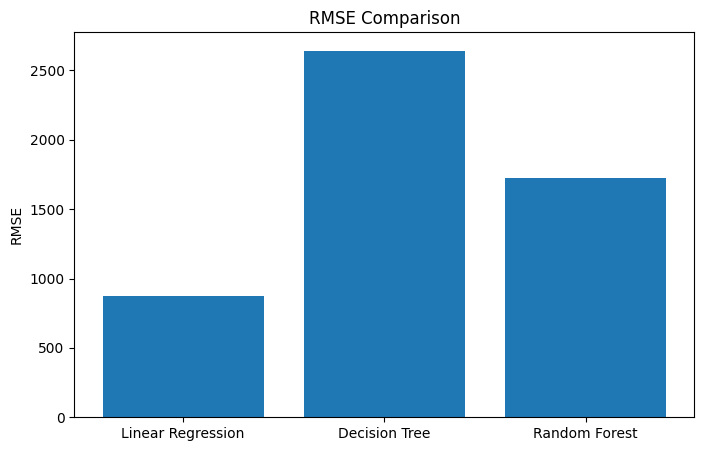

In [ ]:
algorithms = ['Linear Regression', 'Decision Tree', 'Random Forest']
rmse = [875.73, 2642.92, 1725.39]

plt.figure(figsize=(8,5))
plt.bar(algorithms, rmse)
plt.title('RMSE Comparison')
plt.ylabel('RMSE')
plt.show()

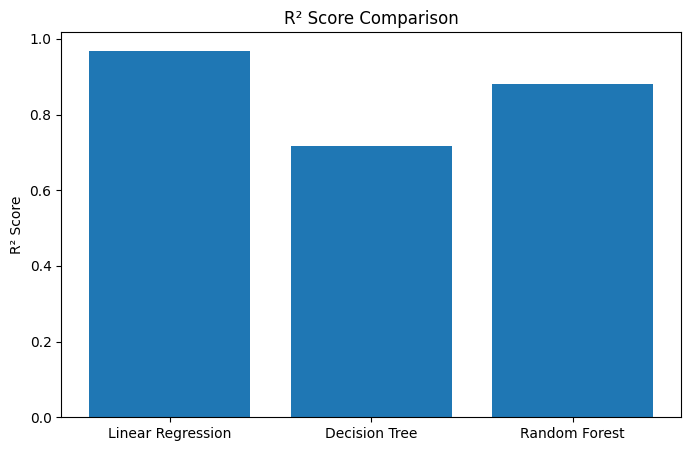

In [ ]:
algorithms = ['Linear Regression', 'Decision Tree', 'Random Forest']
r2 = [0.9691, 0.7182, 0.8799]

plt.figure(figsize=(8,5))
plt.bar(algorithms, r2)
plt.title('R² Score Comparison')
plt.ylabel('R² Score')
plt.show()

### Saving the Best Model

Now that we've identified the Linear Regression model as the best performer, we'll save it to a file. This saved model can then be loaded by a web application for making predictions.

### Re-saving the Model and Verifying its Presence

In [ ]:
import joblib
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# --- Data Loading and Preprocessing (copied from previous cells to ensure scope) ---

# Load the dataset
df = pd.read_excel('/content/drive/MyDrive/Lab_Data/student_expense_dataset.xlsx')

# Clean column names
df.columns = df.columns.str.strip()

# Define features (X) and target (y)
X = df[['Rent',
        'Utilities',
        'Food Expense',
        'Travel Cost',
        'Clothing',
        'Outings']]
y = df['Monthly Expense']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# --- Model Training and Saving ---

# Re-train the model to ensure 'lr' is defined and uses the correct data
lr = LinearRegression()
lr.fit(X_train, y_train)

# Save the Linear Regression model again to ensure it's in the current directory
joblib.dump(lr, 'linear_regression_model.pkl')

print("Linear Regression model re-saved as 'linear_regression_model.pkl'")

# Verify the file is now in the current working directory
if 'linear_regression_model.pkl' in os.listdir():
    print("'linear_regression_model.pkl' found in the current directory.")
else:
    print("Error: 'linear_regression_model.pkl' is still not found after saving. Please check the file path.")

Linear Regression model re-saved as 'linear_regression_model.pkl'
'linear_regression_model.pkl' found in the current directory.


Now that we've ensured the model file is present, we need to stop the currently running Streamlit app and ngrok tunnel, then restart them so the app can correctly load the model. Execute the following cells sequentially.

In [ ]:
from pyngrok import ngrok
import subprocess

# Assuming streamlit_process is a global variable from the deployment cell
global streamlit_process

# Terminate the Streamlit process if it was started
if 'streamlit_process' in globals() and streamlit_process is not None and streamlit_process.poll() is None:
    print("Terminating Streamlit app...")
    streamlit_process.terminate()
    streamlit_process.wait(timeout=5) # Give it some time to shut down
    if streamlit_process.poll() is None:
        print("Streamlit app did not terminate gracefully, killing it...")
        streamlit_process.kill()
    streamlit_process = None # Clear the reference

# Kill the ngrok tunnel
ngrok.kill()
print("ngrok tunnel and Streamlit app stopped.")

ngrok tunnel and Streamlit app stopped.


Now, let's restart the Streamlit app and ngrok tunnel.

In [ ]:
import threading
import time
import subprocess
from pyngrok import ngrok
from google.colab import userdata

# Global variable to store the Streamlit process
global streamlit_process

# Define the port to be used by Streamlit and ngrok
STREAMLIT_PORT = 8502 # Use the same port as defined previously

def run_streamlit():
    global streamlit_process
    # Run Streamlit in the background
    cmd = ['streamlit', 'run', 'streamlit_app.py', '--server.port', str(STREAMLIT_PORT), '--server.enableCORS', 'false', '--browser.gatherUsageStats', 'false']
    streamlit_process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    # Keep the process alive. It will be terminated explicitly in the stop cell.

# Start Streamlit in a separate thread
streamlit_thread = threading.Thread(target=run_streamlit)
streamlit_thread.daemon = True # Allow the main program to exit even if thread is running
streamlit_thread.start()

print("Waiting for Streamlit to start...")
time.sleep(10) # Give Streamlit some time to start up

# Authenticate ngrok if not already
NGROK_AUTH_TOKEN = userdata.get('NGROK_AUTH_TOKEN')
if NGROK_AUTH_TOKEN is not None:
    # Use ngrok.set_auth_token() as ngrok.get_default() might not be available or used differently
    ngrok.set_auth_token(NGROK_AUTH_TOKEN)

# Create a ngrok tunnel to the Streamlit app
try:
    # Disconnect any previous ngrok tunnels (should be handled by the stop cell, but good to ensure)
    ngrok.kill()

    print("Starting ngrok tunnel...")
    public_url = ngrok.connect(STREAMLIT_PORT) # Connect to the specified port
    print(f"Your Streamlit app is live at: {public_url}")
    print("Click the URL above to open your Streamlit application.")
    print("To stop the tunnel and the Streamlit app, execute the last cell in this section.")
except Exception as e:
    print(f"Failed to start ngrok tunnel: {e}")

Waiting for Streamlit to start...
Starting ngrok tunnel...
Your Streamlit app is live at: NgrokTunnel: "https://2551-34-81-32-85.ngrok-free.app" -> "http://localhost:8502"
Click the URL above to open your Streamlit application.
To stop the tunnel and the Streamlit app, execute the last cell in this section.


In [ ]:
import joblib

# Save the Linear Regression model
joblib.dump(lr, 'linear_regression_model.pkl')

print("Linear Regression model saved as 'linear_regression_model.pkl'")

Linear Regression model saved as 'linear_regression_model.pkl'


### Creating a Flask Web Application

We will now create a simple Flask application. This app will:
1.  Load the saved `linear_regression_model.pkl`.
2.  Define an API endpoint (`/predict`) that accepts new data.
3.  Use the loaded model to make predictions based on the input data.
4.  Return the predictions as a JSON response.

In [ ]:
# Install Flask and Flask-Ngrok for local testing in Colab
!pip install Flask Flask-Ngrok


In [ ]:
import joblib
from flask import Flask, request, jsonify
from flask_ngrok import run_with_ngrok
import pandas as pd

# Load the trained model
model = joblib.load('linear_regression_model.pkl')

app = Flask(__name__)
run_with_ngrok(app)  # Starts ngrok when app is run

@app.route('/')
def home():
    return "Welcome to the Student Expense Prediction API! Send POST requests to /predict."

@app.route('/predict', methods=['POST'])
def predict():
    try:
        # Get data from POST request
        data = request.get_json(force=True)

        # Convert json to pandas DataFrame
        df_pred = pd.DataFrame(data, index=[0])

        # Ensure columns are in the correct order as the training data
        # Based on how X was defined in the notebook
        expected_columns = ['Rent', 'Utilities', 'Food Expense', 'Travel Cost', 'Clothing', 'Outings']
        df_pred = df_pred[expected_columns]

        # Make prediction
        prediction = model.predict(df_pred)

        # Return prediction
        return jsonify({'monthly_expense_prediction': prediction[0]})

    except Exception as e:
        return jsonify({'error': str(e)}), 400

# To run the app, simply execute this cell.
# Ngrok will provide a public URL for your Flask app.
# app.run()


To start the Flask application and get a public URL from ngrok, you need to run the Python cell above.

Once it's running, you will see a public URL (e.g., `https://xxxx-xxxx-xxxx-xxxx.ngrok-free.app`). You can then send a POST request to `YOUR_NGROK_URL/predict` with JSON data representing a student's expenses.

**Example of data to send in the POST request body (JSON format):**

```json
{
    "Rent": 15000,
    "Utilities": 2500,
    "Food Expense": 4000,
    "Travel Cost": 3000,
    "Clothing": 2000,
    "Outings": 1500
}
```

You can test this using tools like Postman, curl, or even Python's `requests` library in another cell.

### Testing the Flask API

To test the API, you can use the `requests` library to send a POST request with sample data. Remember to replace `YOUR_NGROK_URL` with the actual public URL generated by ngrok.

In [ ]:
import requests
import json

# IMPORTANT: Replace this with the actual ngrok URL you get after running the Flask app cell
# Example: YOUR_NGROK_URL = "https://abcdef12345.ngrok.io"
YOUR_NGROK_URL = "<YOUR_NGROK_URL>"

# The endpoint for predictions
predict_url = f"{YOUR_NGROK_URL}/predict"

# Sample data for prediction (similar to X_test input format)
# Ensure the keys match the 'expected_columns' in the Flask app
sample_data = {
    "Rent": 15000,
    "Utilities": 2500,
    "Food Expense": 4000,
    "Travel Cost": 3000,
    "Clothing": 2000,
    "Outings": 1500
}

# Send the POST request
headers = {'Content-Type': 'application/json'}
response = requests.post(predict_url, data=json.dumps(sample_data), headers=headers)

# Print the response
if response.status_code == 200:
    print("Prediction successful:")
    print(response.json())
else:
    print(f"Error: {response.status_code} - {response.text}")


After running the Flask application cell, copy the ngrok URL it provides and paste it into the `YOUR_NGROK_URL` variable in the cell above. Then run the test cell to see the prediction from your deployed model!

### Deploying with Streamlit

Streamlit provides a simpler way to create interactive web applications for your machine learning models. Let's create a Streamlit app to showcase our Linear Regression model.

In [ ]:
# Install Streamlit
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 51.0 MB/s eta 0:00:00


Next, we'll create the `streamlit_app.py` file. This file will contain the code for our web application.

In [ ]:
%%writefile streamlit_app.py

import streamlit as st
import joblib
import pandas as pd

st.set_page_config(
    page_title="Student Expense Predictor",
    page_icon="💰",
    layout="centered",
    initial_sidebar_state="expanded",
)

st.title("💰 Student Monthly Expense Predictor")
st.markdown("--- ")

# Load the trained Linear Regression model
# Make sure 'linear_regression_model.pkl' is in the same directory as this script
try:
    model = joblib.load('linear_regression_model.pkl')
except FileNotFoundError:
    st.error("Error: 'linear_regression_model.pkl' not found. Please ensure the model file is in the correct directory.")
    st.stop()

st.header("Input Student Financials")

# Create input fields for each feature
rent = st.number_input("Rent (in INR)", min_value=0, value=15000, step=100)
utilities = st.number_input("Utilities (in INR)", min_value=0, value=2500, step=100)
food_expense = st.number_input("Food Expense (in INR)", min_value=0, value=4000, step=100)
travel_cost = st.number_input("Travel Cost (in INR)", min_value=0, value=3000, step=100)
clothing = st.number_input("Clothing (in INR)", min_value=0, value=2000, step=100)
outings = st.number_input("Outings (in INR)", min_value=0, value=1500, step=100)

# Prepare input for prediction
input_data = pd.DataFrame([{
    'Rent': rent,
    'Utilities': utilities,
    'Food Expense': food_expense,
    'Travel Cost': travel_cost,
    'Clothing': clothing,
    'Outings': outings
}])

if st.button("Predict Monthly Expense"):
    prediction = model.predict(input_data)[0]
    st.success(f"Predicted Monthly Expense: ₹{prediction:,.2f}")

st.markdown("--- ")
st.write("This application predicts the monthly expenses of a student based on various financial inputs.")


Writing streamlit_app.py


Now that the `streamlit_app.py` file is created, you can run the Streamlit application. This will provide you with a public URL that you can open in your browser.

In [ ]:
# This cell previously ran Streamlit in the foreground for debugging.
# It has been removed as the primary deployment method now uses ngrok in the background.
# Please proceed to the next cells for ngrok deployment.

In [ ]:
import subprocess

# Kill any running Streamlit processes to avoid conflicts
subprocess.run(['killall', 'streamlit'], capture_output=True, text=True)
print('Attempted to stop all Streamlit processes.')


Attempted to stop all Streamlit processes.


### Set up ngrok Authentication Token

To use ngrok, you need an authentication token. If you don't have one, sign up at [ngrok.com](https://ngrok.com) and get your auth token from the dashboard.

Once you have your token, add it to Colab's secrets manager (click the "🔑" icon in the left panel) with the name `NGROK_AUTH_TOKEN`.

In [ ]:
# Install pyngrok to ensure it's available for import
!pip install pyngrok

from pyngrok import ngrok, conf
from google.colab import userdata

# Get ngrok auth token from Colab secrets
NGROK_AUTH_TOKEN = userdata.get('NGROK_AUTH_TOKEN')

if NGROK_AUTH_TOKEN is None:
    print("Error: NGROK_AUTH_TOKEN not found in Colab secrets. Please add it.")
else:
    # Authenticate ngrok
    conf.get_default().auth_token = NGROK_AUTH_TOKEN
    print("ngrok authenticated successfully!")

ngrok authenticated successfully!


### Run Streamlit app with ngrok

Now, run the Streamlit app in the background and expose it using ngrok. This will provide a public URL to access your app.

In [ ]:
import threading
import time
import subprocess
from pyngrok import ngrok

# Global variable to store the Streamlit process
streamlit_process = None

# Define the port to be used by Streamlit and ngrok
STREAMLIT_PORT = 8502 # Changed port to 8502

def run_streamlit():
    global streamlit_process
    # Run Streamlit in the background
    cmd = ['streamlit', 'run', 'streamlit_app.py', '--server.port', str(STREAMLIT_PORT), '--server.enableCORS', 'false', '--browser.gatherUsageStats', 'false']
    streamlit_process = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
    # Keep the process alive. It will be terminated explicitly in the stop cell.

# Start Streamlit in a separate thread
streamlit_thread = threading.Thread(target=run_streamlit)
streamlit_thread.daemon = True # Allow the main program to exit even if thread is running
streamlit_thread.start()

print("Waiting for Streamlit to start...")
time.sleep(10) # Give Streamlit some time to start up

# Create a ngrok tunnel to the Streamlit app
try:
    # Disconnect any previous ngrok tunnels
    ngrok.kill()

    print("Starting ngrok tunnel...")
    public_url = ngrok.connect(STREAMLIT_PORT) # Connect to the specified port
    print(f"Your Streamlit app is live at: {public_url}")
    print("Click the URL above to open your Streamlit application.")
    print("To stop the tunnel and the Streamlit app, execute the last cell in this section.")
except Exception as e:
    print(f"Failed to start ngrok tunnel: {e}")

Waiting for Streamlit to start...
Starting ngrok tunnel...
Your Streamlit app is live at: NgrokTunnel: "https://24aa-34-81-32-85.ngrok-free.app" -> "http://localhost:8502"
Click the URL above to open your Streamlit application.
To stop the tunnel and the Streamlit app, execute the last cell in this section.


In [ ]:
from pyngrok import ngrok
import subprocess

# Assuming streamlit_process is a global variable from the deployment cell
global streamlit_process

# Terminate the Streamlit process if it was started
if 'streamlit_process' in globals() and streamlit_process is not None and streamlit_process.poll() is None:
    print("Terminating Streamlit app...")
    streamlit_process.terminate()
    streamlit_process.wait(timeout=5) # Give it some time to shut down
    if streamlit_process.poll() is None:
        print("Streamlit app did not terminate gracefully, killing it...")
        streamlit_process.kill()
    streamlit_process = None # Clear the reference

# Kill the ngrok tunnel
ngrok.kill()
print("ngrok tunnel and Streamlit app stopped.")


Terminating Streamlit app...
ngrok tunnel and Streamlit app stopped.


Once you run the last cell, you should see a public URL. Click on that URL to interact with your Streamlit application! You can adjust the input values and click 'Predict Monthly Expense' to get predictions from your model.